In [1]:
import pandas as pd
import numpy as np

# List your replicate files
files = ["absorbance/ALKALINE 1.csv", "absorbance/ALKALINE 2.csv", "absorbance/ALKALINE 3.csv", "absorbance/ALKALINE 4.csv", "absorbance/ALKALINE 5.csv", "absorbance/ALKALINE 6.csv", "absorbance/ALKALINE 8.csv"]

# Read each file into a DataFrame
dfs = [pd.read_csv(f, comment='#') for f in files]

# Extract wavenumber column (assumed identical across replicates)
wn = dfs[0].iloc[:, 0].values.astype(float)

# Stack absorbance columns from each replicate
absorbances = np.array([df.iloc[:, 1].values for df in dfs], dtype=float)

# Compute the average absorbance
ab_avg = absorbances.mean(axis=0)

# Create a new DataFrame for saving
avg_df = pd.DataFrame({
    "wn": wn,
    "ab_avg": ab_avg
})

# Save to CSV
avg_df.to_csv("absorbance/ALKALINE_average.csv", index=False)

print("Averaged file saved as absorbance/ALKALINE_average.csv")

Averaged file saved as absorbance/ALKALINE_average.csv


Amide I maximum position: 1633.00 cm⁻¹
Amide I maximum intensity: 0.0886


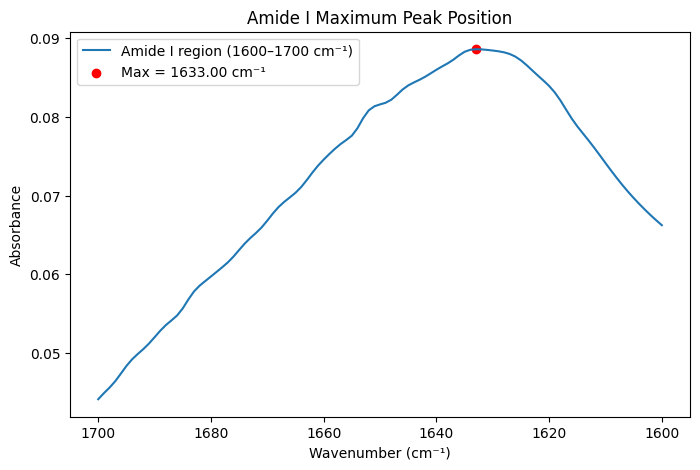

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATA
# ============================================================
#df = pd.read_csv("absorbance/ALKALINE_average.csv", comment='#')
df = pd.read_csv("absorbance/ALKALINE 6.csv", comment='#') #1,4,5,6
wn = df.iloc[:,0].values.astype(float)
ab = df.iloc[:,1].values.astype(float)

# Sort in descending order (for FTIR plotting convention)
idx = np.argsort(wn)[::-1]
wn = wn[idx]
ab = ab[idx]

# ============================================================
# 2. SELECT AMIDE I REGION (1600–1700 cm-1)
# ============================================================
mask = (wn >= 1600) & (wn <= 1700)
x = wn[mask]
y = ab[mask]

# ============================================================
# 3. FIND AMIDE I MAXIMUM
# ============================================================
max_idx = np.argmax(y)
amide_I_max_wavenumber = x[max_idx]
amide_I_max_intensity = y[max_idx]

print(f"Amide I maximum position: {amide_I_max_wavenumber:.2f} cm⁻¹")
print(f"Amide I maximum intensity: {amide_I_max_intensity:.4f}")

# ============================================================
# 4. PLOT
# ============================================================
plt.figure(figsize=(8,5))
plt.plot(x, y, label="Amide I region (1600–1700 cm⁻¹)")
plt.scatter(amide_I_max_wavenumber, amide_I_max_intensity, 
            color='red', label=f"Max = {amide_I_max_wavenumber:.2f} cm⁻¹")
plt.gca().invert_xaxis()
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Absorbance")
plt.legend()
plt.title("Amide I Maximum Peak Position")
plt.show()

# Absorbance

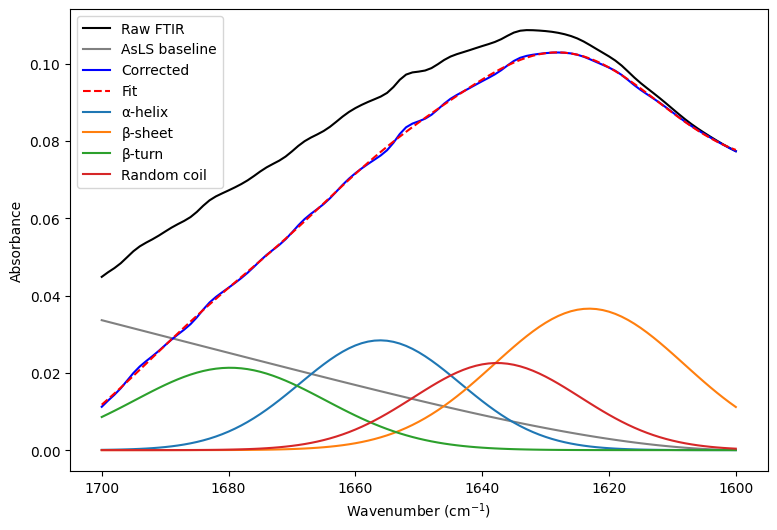

α-helix: 23.61%
β-sheet: 36.00%
β-turn: 20.96%
Random coil: 19.43%


In [ ]:
# absorbance 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve

# ============================================================
# 1. LOAD DATA
# ============================================================
#df = pd.read_csv("absorbance/ALKALINE_average.csv")
df = pd.read_csv("absorbance/ALKALINE 8.csv", comment = "#") #1, 4,5,6
wn = df.iloc[:,0].values.astype(float)
ab = df.iloc[:,1].values.astype(float)

# Sort in descending order (required for plotting)
idx = np.argsort(wn)[::-1]
wn = wn[idx]
ab = ab[idx]

# ============================================================
# 2. SELECT AMIDE I region (1600–1700 cm-1)
# ============================================================
mask = (wn >= 1600) & (wn <= 1700)
x = wn[mask]
y = ab[mask]

# ============================================================
# 3. AsLS BASELINE (dimension-safe version)
# ============================================================
def baseline_asls(y, lam=1e6, p=0.001, niter=10):
    L = len(y)
    D = diags([1, -2, 1], [0, 1, 2], shape=(L, L))
    w = np.ones(L)
    for _ in range(niter):
        W = diags(w, 0, shape=(L, L))
        Z = W + lam * (D.T @ D)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y <= z)
    return z

baseline = baseline_asls(y, lam=1e5, p=0.005, niter=8)
y_corr = y - baseline


# ============================================================
# 4. Gaussian model
# ============================================================
def gaussian(x, amp, cen, wid):
    return amp * np.exp(-(x - cen)**2 / (2 * wid**2))

def model(x, *params):
    out = np.zeros_like(x)
    for i in range(4):
        amp, cen, wid = params[3*i:3*i+3]
        out += gaussian(x, amp, cen, wid)
    # Linear baseline
    b0, b1 = params[-2], params[-1]
    return out + (b0 + b1 * x)

# ============================================================
# 5. INITIAL PEAK ASSIGNMENTS (plant protein typical)
# ============================================================
init = [
    0.02, 1654, 7,    # α-helix
    0.02, 1625, 7,    # β-sheet
    0.02, 1672, 7,    # β-turn
    0.02, 1642, 7,    # Random coil
    0, 0              # baseline
]


lower = [
    0.003, 1648, 3,
    0.003, 1618, 3,
    0.003, 1660, 3,
    0.003, 1636, 3,
    -np.inf, -np.inf
]

upper = [
    0.2, 1660, 15,
    0.2, 1632, 15,
    0.2, 1680, 15,
    0.2, 1648, 15,
    np.inf, np.inf
]



# ============================================================
# 6. FITTING
# ============================================================
popt, _ = curve_fit(model, x, y_corr, p0=init, bounds=(lower, upper), maxfev=200000)

# ============================================================
# 7. COMPUTE AREAS
# ============================================================
labels = ["α-helix", "β-sheet", "β-turn", "Random coil"]
areas = []
components = []

for i in range(4):
    amp, cen, wid = popt[3*i:3*i+3]
    comp = gaussian(x, amp, cen, wid)
    components.append(comp)
    area = amp * wid * np.sqrt(2*np.pi)
    areas.append(area)

areas = np.array(areas)
percentages = 100 * areas / areas.sum()

# ============================================================
# 8. PLOT RESULTS
# ============================================================
plt.figure(figsize=(9,6))
plt.plot(x, y, "k", label="Raw FTIR")
plt.plot(x, baseline, "gray", label="AsLS baseline")
plt.plot(x, y_corr, "b", label="Corrected")
plt.plot(x, model(x, *popt), "r--", label="Fit")

for comp, lab in zip(components, labels):
    plt.plot(x, comp, label=lab)

plt.gca().invert_xaxis()
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

# ============================================================
# 9. PRINT STRUCTURAL % RESULTS
# ============================================================
for lab, pct in zip(labels, percentages):
    print(f"{lab}: {pct:.2f}%")


In [2]:
# ============================================================
# 10. PRINT FITTED PARAMETERS (amp, center, width)
# ============================================================
for i, lab in enumerate(labels):
    amp, cen, wid = popt[3*i:3*i+3]
    print(f"{lab}: amp={amp:.3f}, center={cen:.2f} cm-1, width={wid:.2f}")


α-helix: amp=0.032, center=1655.44 cm-1, width=12.31
β-sheet: amp=0.040, center=1622.20 cm-1, width=15.00
β-turn: amp=0.025, center=1678.74 cm-1, width=15.00
Random coil: amp=0.029, center=1636.77 cm-1, width=13.18


In [3]:
def refit_with_perturb(scale=0.03, trials=10):
    rng = np.random.default_rng(0)
    results = []
    for _ in range(trials):
        p0 = init.copy()
        for i in range(4):
            a,c,w = p0[3*i:3*i+3]
            p0[3*i] = max(0.1, a * (1 + rng.normal(0, scale)))    # amp
            p0[3*i+1] = c + rng.normal(0, 1.0)                     # center (±1 cm-1)
            p0[3*i+2] = min(max(3, w * (1 + rng.normal(0, scale))), 15)  # width
        p0[-2] += rng.normal(0, 0.01); p0[-1] += rng.normal(0, 1e-4)
        popt_i, _ = curve_fit(model, x, y_corr, p0=p0, bounds=(lower, upper), maxfev=200000)
        # areas
        areas_i = []
        for i in range(4):
            a,c,w = popt_i[3*i:3*i+3]
            areas_i.append(a * w * np.sqrt(2*np.pi))
        pct_i = 100 * np.array(areas_i) / np.sum(areas_i) if np.sum(areas_i)>0 else np.zeros(4)
        results.append((popt_i, pct_i))
    return results

results = refit_with_perturb()
pct_stack = np.vstack([r[1] for r in results])
print("Percentiles of component % (rows: trials):")
print(pd.DataFrame(pct_stack, columns=labels))
print("Std dev of %:", pd.DataFrame(pct_stack, columns=labels).std())


Percentiles of component % (rows: trials):
     α-helix    β-sheet     β-turn  Random coil
0  24.054187  30.860321  20.802476    24.283016
1  23.963196  30.779398  20.796590    24.460816
2  24.489542  31.535022  20.799436    23.176000
3  22.026075  27.604283  22.701093    27.668549
4  24.038910  30.830230  20.801430    24.329431
5  23.535339  32.213111  20.905420    23.346131
6  24.085506  27.399176  21.167136    27.348181
7  24.412546  33.863267  21.167631    20.556556
8  20.652865  29.155997  22.235261    27.955876
9  24.334313  31.292868  20.801030    23.571789
Std dev of %: α-helix        1.243101
β-sheet        2.001147
β-turn         0.683947
Random coil    2.342401
dtype: float64


In [4]:
rss = np.sum((y_corr - model(x, *popt))**2)
n = len(x)
k = len(popt)
rmse = np.sqrt(rss / n)
aic = n * np.log(rss / n) + 2 * k
bic = n * np.log(rss / n) + k * np.log(n)
print(f"RMSE: {rmse:.5f}, AIC: {aic:.2f}, BIC: {bic:.2f}")


RMSE: 0.00039, AIC: -1557.51, BIC: -1520.90


Detected peaks in Amide I region:
  1601.0 cm⁻¹
  1610.0 cm⁻¹
  1621.0 cm⁻¹
  1627.0 cm⁻¹
  1633.0 cm⁻¹
  1643.0 cm⁻¹
  1652.0 cm⁻¹
  1661.0 cm⁻¹
  1670.0 cm⁻¹
  1682.0 cm⁻¹
  1694.0 cm⁻¹

Kong & Yu (2007) reference assignments:
  ~1609 cm⁻¹  →  side chain
  ~1620 cm⁻¹  →  intermolecular β-sheet
  ~1628 cm⁻¹  →  β-sheet
  ~1638 cm⁻¹  →  β-sheet
  ~1645 cm⁻¹  →  random coil
  ~1655 cm⁻¹  →  α-helix
  ~1665 cm⁻¹  →  β-turn
  ~1675 cm⁻¹  →  β-turn/sheet
  ~1687 cm⁻¹  →  β-sheet/turn


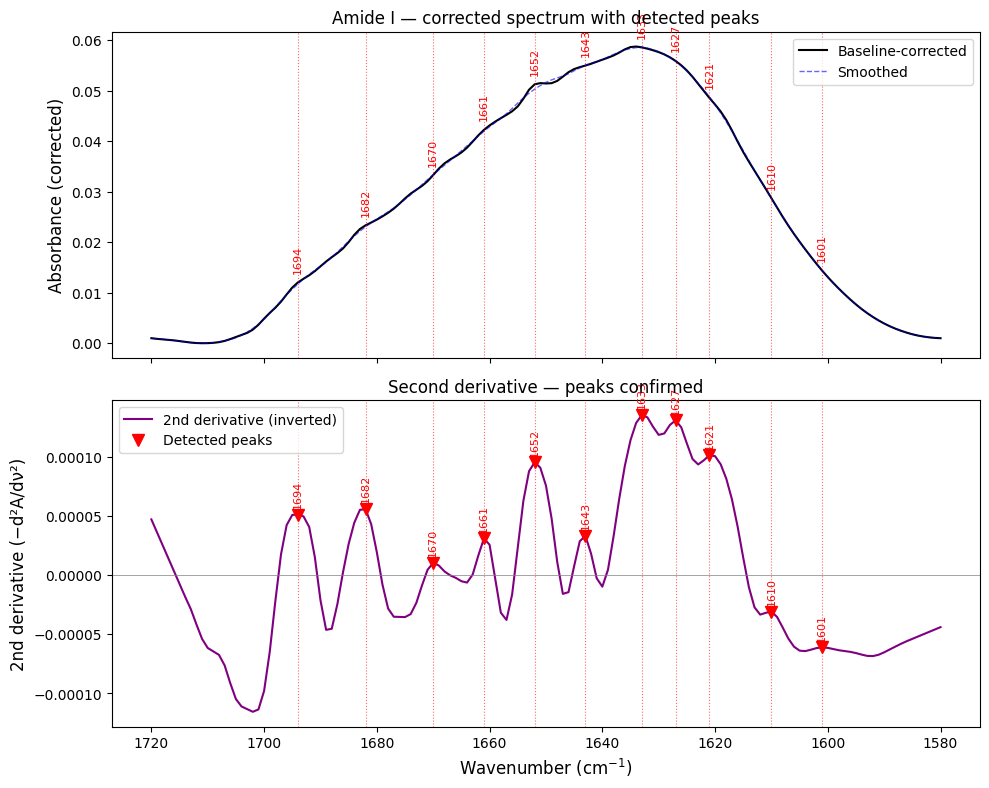

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv("absorbance/ALKALINE_average.csv")
wn = df.iloc[:, 0].values.astype(float)
ab = df.iloc[:, 1].values.astype(float)

idx = np.argsort(wn)[::-1]
wn = wn[idx]
ab = ab[idx]

# ============================================================
# 2. SELECT AMIDE I REGION (1580–1720 cm-1)
# ============================================================
mask = (wn >= 1580) & (wn <= 1720)
x = wn[mask]
y = ab[mask]

# ============================================================
# 3. SIMPLE LINEAR BASELINE using endpoints
# This is more reliable than AsLS when the spectrum has a
# strong slope — draws a straight line from the value at
# 1720 cm-1 to the value at 1580 cm-1 and subtracts it.
# ============================================================
x_start, x_end = x[0], x[-1]     # 1720 and 1580
y_start, y_end = y[0], y[-1]

linear_baseline = y_start + (y_end - y_start) * (x - x_start) / (x_end - x_start)
y_corr = y - linear_baseline

# Ensure no negative values (shift up if needed)
if y_corr.min() < 0:
    y_corr = y_corr - y_corr.min()

# ============================================================
# 4. SECOND DERIVATIVE
# window_length: increase to smooth more, decrease to resolve
# more peaks. Must be odd.
# ============================================================
window_length = 13# <-- ADJUST: try 11, 13, 15, 17, 21
polyorder     = 3

y_smooth   = savgol_filter(y_corr, window_length=window_length, polyorder=polyorder)
y_deriv2   = savgol_filter(y_corr, window_length=window_length, polyorder=polyorder,
                           deriv=2)
y_deriv2_inv = -y_deriv2

# ============================================================
# 5. PEAK DETECTION
# prominence: lower = more peaks, higher = fewer strong peaks
# ============================================================
prominence   = 0.000001 # <-- ADJUST if too many or too few peaks
min_distance = 3

peaks_idx, _ = find_peaks(
    y_deriv2_inv,
    prominence=prominence,
    distance=min_distance
)

peak_wavenumbers = x[peaks_idx]
peak_heights     = y_corr[peaks_idx]

print("=" * 50)
print("Detected peaks in Amide I region:")
print("=" * 50)
for wn_val in sorted(peak_wavenumbers):
    ht = y_corr[list(x).index(wn_val)] if wn_val in x else 0
    print(f"  {wn_val:.1f} cm⁻¹")

print()
print("Kong & Yu (2007) reference assignments:")
ref = {1609: "side chain", 1620: "intermolecular β-sheet",
       1628: "β-sheet", 1638: "β-sheet", 1645: "random coil",
       1655: "α-helix", 1665: "β-turn", 1675: "β-turn/sheet",
       1687: "β-sheet/turn"}
for wn_ref, label in ref.items():
    print(f"  ~{wn_ref} cm⁻¹  →  {label}")

# ============================================================
# 6. PLOT
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Top: corrected spectrum
ax1.plot(x, y_corr, 'k', linewidth=1.5, label="Baseline-corrected")
ax1.plot(x, y_smooth, 'b--', linewidth=1, alpha=0.6, label="Smoothed")
for wn_val, ht in zip(peak_wavenumbers, peak_heights):
    ax1.axvline(wn_val, color='red', linestyle=':', alpha=0.6, linewidth=0.8)
    ax1.annotate(f"{wn_val:.0f}",
                 xy=(wn_val, ht),
                 xytext=(0, 8),
                 textcoords="offset points",
                 ha='center', fontsize=8, color='red', rotation=90)
ax1.set_ylabel("Absorbance (corrected)", fontsize=12)
ax1.legend(fontsize=10)
ax1.set_title("Amide I — corrected spectrum with detected peaks", fontsize=12)

# Bottom: second derivative
ax2.plot(x, y_deriv2_inv, 'purple', linewidth=1.5,
         label="2nd derivative (inverted)")
ax2.plot(x[peaks_idx], y_deriv2_inv[peaks_idx], 'rv',
         markersize=8, label="Detected peaks")
for wn_val in peak_wavenumbers:
    ax2.axvline(wn_val, color='red', linestyle=':', alpha=0.6, linewidth=0.8)
    ax2.annotate(f"{wn_val:.0f}",
                 xy=(wn_val, y_deriv2_inv[peaks_idx[list(peak_wavenumbers).index(wn_val)]]),
                 xytext=(0, 6),
                 textcoords="offset points",
                 ha='center', fontsize=8, color='red', rotation=90)
ax2.axhline(0, color='gray', linewidth=0.5)
ax2.set_xlabel("Wavenumber (cm$^{-1}$)", fontsize=12)
ax2.set_ylabel("2nd derivative (−d²A/dν²)", fontsize=12)
ax2.legend(fontsize=10)
ax2.set_title("Second derivative — peaks confirmed", fontsize=12)

plt.gca().invert_xaxis()
plt.tight_layout()
plt.savefig("FTIR_peak_detection.png", dpi=300, bbox_inches="tight")
plt.show()

Max corrected absorbance: 0.05817
✓ All counts match — safe to fit

Fit quality: RMSE=0.00090, AIC=-1779.20, BIC=-1695.82
(Original 4-band Gaussian: RMSE=0.00671, AIC=-982.71)
Lower RMSE and more negative AIC/BIC = better fit

β-sheet: 38.32%
α-helix: 15.24%
random coil: 30.01%
β-turn: 16.42%

Fitted parameters:
β-sheet: amp=0.0391, center=1620.00 cm-1, width=12.50
β-sheet: amp=0.0079, center=1627.96 cm-1, width=3.20
β-sheet: amp=0.0137, center=1633.50 cm-1, width=5.12
random coil: amp=0.0382, center=1642.34 cm-1, width=12.50
α-helix: amp=0.0107, center=1652.13 cm-1, width=5.56
α-helix: amp=0.0186, center=1660.52 cm-1, width=9.32
β-turn: amp=0.0154, center=1670.95 cm-1, width=10.25
β-turn: amp=0.0121, center=1682.86 cm-1, width=8.54
β-sheet: amp=0.0056, center=1693.41 cm-1, width=5.04


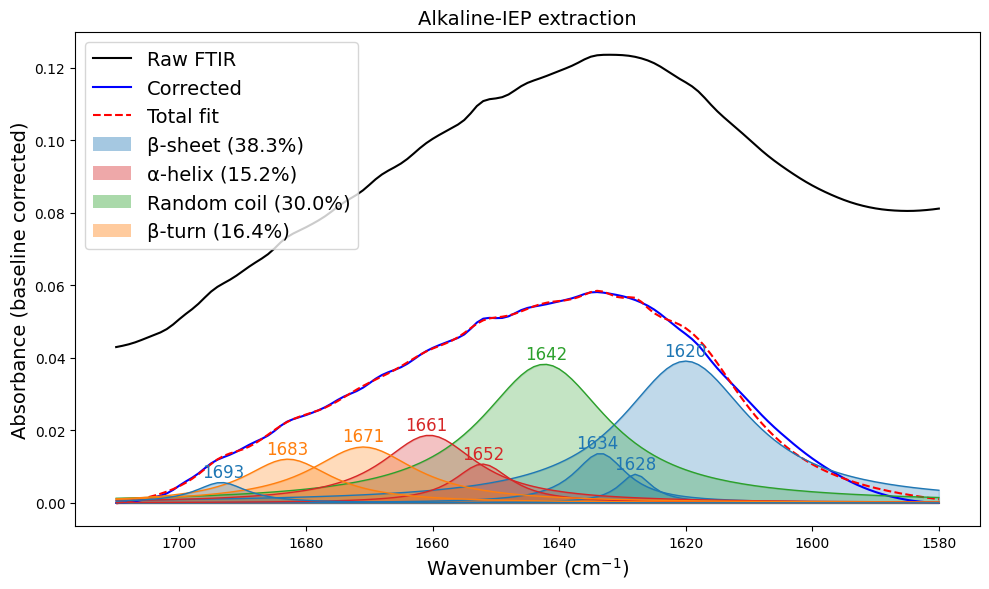

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import simpson

# ============================================================
# 1. LOAD DATA — update filename for each sample
# ============================================================
df = pd.read_csv("absorbance/ALKALINE_average.csv")
wn = df.iloc[:, 0].values.astype(float)
ab = df.iloc[:, 1].values.astype(float)

idx = np.argsort(wn)[::-1]
wn = wn[idx]
ab = ab[idx]

# ============================================================
# 2. SELECT AMIDE I REGION (1580–1710 cm-1)
# Side chains excluded by window — no need to fit them
# ============================================================
mask = (wn >= 1580) & (wn <= 1710)
x = wn[mask]
y = ab[mask]

# ============================================================
# 3. LINEAR BASELINE CORRECTION
# ============================================================
y_start, y_end = y[0], y[-1]
x_start, x_end = x[0], x[-1]
linear_baseline = y_start + (y_end - y_start) * (x - x_start) / (x_end - x_start)
y_corr = y - linear_baseline
if y_corr.min() < 0:
    y_corr = y_corr - y_corr.min()

scale = y_corr.max()
print(f"Max corrected absorbance: {scale:.5f}")

# ============================================================
# 4. LORENTZIAN MODEL
# Broader tails than Gaussian — better fit for protein amide I
# Only amplitude and width vary — centres FIXED from 2nd derivative
# ============================================================
def lorentzian(x, amp, cen, wid):
    return amp * (wid**2 / ((x - cen)**2 + wid**2))

def model(x, *params):
    out = np.zeros_like(x, dtype=float)
    n_peaks = (len(params) - 2) // 3
    for i in range(n_peaks):
        amp, cen, wid = params[3*i], params[3*i+1], params[3*i+2]
        out += lorentzian(x, amp, cen, wid)
    b0, b1 = params[-2], params[-1]
    return out + (b0 + b1 * x)

# ============================================================
# 5. PEAK ASSIGNMENTS
# Centres fixed from second derivative detection
# General spectroscopic assignments:
#   1620–1640  β-sheet
#   1640–1650  random coil
#   1650–1660  α-helix
#   1660–1670  α-helix disordered / 310 helix
#   1670–1685  β-turn
#   1685–1700  antiparallel β-sheet
#
# UPDATE labels and centres for each sample
# ============================================================
peak_centres = [1621, 1627, 1633, 1643, 1652, 1661, 1670, 1682, 1694]

labels = [
    "β-sheet",       # 1621 — intermolecular β-sheet
    "β-sheet",       # 1627 — β-sheet
    "β-sheet",       # 1633 — intramolecular β-sheet dominant
    "random coil",   # 1643 — disordered structures
    "α-helix",       # 1652 — α-helix
    "α-helix",       # 1661 — α-helix disordered / 310 helix
    "β-turn",        # 1670 — β-turn
    "β-turn",        # 1682 — β-turn / antiparallel β-sheet
    "β-sheet",       # 1694 — antiparallel β-sheet high wavenumber
]

n_peaks = len(peak_centres)

# ============================================================
# 6. INITIAL PARAMETERS AND BOUNDS
# Centre bounds: fixed to ±1 cm-1 (effectively fixed)
# Width bounds: 3–12 cm-1
# Amplitude: 0 to 2×scale
# α-helix has minimum amplitude enforced
# ============================================================
init, lower, upper = [], [], []

amp_inits = {
    1621: scale*0.55,
    1627: scale*0.75,
    1633: scale*1.00,   # dominant band
    1643: scale*0.75,
    1652: scale*0.65,
    1661: scale*0.50,
    1670: scale*0.35,
    1682: scale*0.25,
    1694: scale*0.12,
}

for i, (cen, lab) in enumerate(zip(peak_centres, labels)):
    amp0    = amp_inits.get(cen, scale*0.30)
    amp_min = scale*0.02 if lab == "α-helix" else 0.0
    init  += [amp0,     cen,    6.0]
    lower += [amp_min,  cen-1,  3.0]   # centre fixed ±1 cm-1
    upper += [scale*2,  cen+1,  12.5]

# Linear baseline
init  += [0, 0]
lower += [-np.inf, -np.inf]
upper += [np.inf,  np.inf]

# ============================================================
# 7. VERIFY COUNTS
# ============================================================
assert len(labels) == (len(init) - 2) // 3, \
    f"Labels ({len(labels)}) don't match init bands ({(len(init)-2)//3})"
assert len(lower) == len(init), \
    f"Lower bounds ({len(lower)}) don't match init ({len(init)})"
assert len(upper) == len(init), \
    f"Upper bounds ({len(upper)}) don't match init ({len(init)})"
print("✓ All counts match — safe to fit")

# ============================================================
# 8. FIT
# ============================================================
popt, pcov = curve_fit(
    model, x, y_corr,
    p0=init, bounds=(lower, upper),
    maxfev=500000
)

# ============================================================
# 9. COMPUTE AREAS — numerical integration (more accurate)
# ============================================================
group_names  = ["β-sheet", "α-helix", "random coil", "β-turn"]
group_areas  = {g: 0.0 for g in group_names}
protein_total = 0.0
components, areas, centres_fit = [], [], []

for i in range(n_peaks):
    amp, cen, wid = popt[3*i], popt[3*i+1], popt[3*i+2]
    comp = lorentzian(x, amp, cen, wid)
    area = simpson(comp, x=x)           # numerical integration
    components.append(comp)
    areas.append(area)
    centres_fit.append(cen)
    group_areas[labels[i]] += area
    protein_total           += area

percentages = {g: 100 * group_areas[g] / protein_total for g in group_names}

# ============================================================
# 10. FIT QUALITY
# ============================================================
y_fit = model(x, *popt)
rss   = np.sum((y_corr - y_fit)**2)
n, k  = len(x), len(popt)
rmse  = np.sqrt(rss / n)
aic   = n * np.log(rss / n) + 2 * k
bic   = n * np.log(rss / n) + k * np.log(n)

print(f"\nFit quality: RMSE={rmse:.5f}, AIC={aic:.2f}, BIC={bic:.2f}")
print(f"(Original 4-band Gaussian: RMSE=0.00671, AIC=-982.71)")
print(f"Lower RMSE and more negative AIC/BIC = better fit\n")

# ============================================================
# 11. PRINT RESULTS
# ============================================================
print("=" * 50)
for g in group_names:
    print(f"{g}: {percentages[g]:.2f}%")
print("=" * 50)

print("\nFitted parameters:")
for i, lab in enumerate(labels):
    amp, cen, wid = popt[3*i], popt[3*i+1], popt[3*i+2]
    print(f"{lab}: amp={amp:.4f}, center={cen:.2f} cm-1, width={wid:.2f}")

# ============================================================
# 12. PLOT
# ============================================================
colors = {
    "β-sheet":     "#1f77b4",
    "random coil": "#2ca02c",
    "α-helix":     "#d62728",
    "β-turn":      "#ff7f0e",
}

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y,      "k",   linewidth=1.5, label="Raw FTIR")
ax.plot(x, y_corr, "b",   linewidth=1.5, label="Corrected")
ax.plot(x, y_fit,  "r--", linewidth=1.5, label="Total fit")

for comp, lab, cen in zip(components, labels, centres_fit):
    color = colors[lab]
    ax.fill_between(x, comp, alpha=0.28, color=color)
    ax.plot(x, comp, color=color, linewidth=1)
    pk = np.argmax(comp)
    ax.annotate(f"{cen:.0f}",
                xy=(x[pk], comp[pk]),
                xytext=(0, 4), textcoords="offset points",
                ha='center', fontsize=12, color=color)

from matplotlib.patches import Patch
legend_elems = [
    plt.Line2D([0],[0], color='k', lw=1.5, label='Raw FTIR'),
    plt.Line2D([0],[0], color='b', lw=1.5, label='Corrected'),
    plt.Line2D([0],[0], color='r', lw=1.5, ls='--', label='Total fit'),
    Patch(facecolor='#1f77b4', alpha=0.4,
          label=f'β-sheet ({percentages["β-sheet"]:.1f}%)'),
    Patch(facecolor='#d62728', alpha=0.4,
          label=f'α-helix ({percentages["α-helix"]:.1f}%)'),
    Patch(facecolor='#2ca02c', alpha=0.4,
          label=f'Random coil ({percentages["random coil"]:.1f}%)'),
    Patch(facecolor='#ff7f0e', alpha=0.4,
          label=f'β-turn ({percentages["β-turn"]:.1f}%)'),
]
ax.legend(handles=legend_elems, loc='upper left', fontsize=14)
ax.invert_xaxis()
ax.set_xlabel("Wavenumber (cm$^{-1}$)", fontsize=14)
ax.set_ylabel("Absorbance (baseline corrected)", fontsize=14)
ax.set_title("Alkaline-IEP extraction", fontsize=14)
plt.tight_layout()
plt.savefig("FTIR_secondary_structure.png", dpi=600, bbox_inches="tight")
plt.show()